In [2]:

# ============================================================
# NOTEBOOK 2: EDA AND FEATURE ENGINEERING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")
OUT = "/content/Software-Quality-Insight"
PLOTS = f"{OUT}/visualizations"
PROCESSED = f"{OUT}/data/processed"

os.makedirs(PLOTS, exist_ok=True)
os.makedirs(PROCESSED, exist_ok=True)

uploaded = files.upload()
csv_file = next(
    (n for n in uploaded if n.lower().endswith(".csv")), None
)
if csv_file is None:
    raise ValueError("Upload software_quality_cleaned.csv")

df = pd.read_csv(csv_file)
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.describe(include="all").T)


Saving software_quality_cleaned.csv to software_quality_cleaned.csv
Dataset shape: (50, 15)
Columns: ['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage', 'component', 'language', 'size', 'defect_count', 'severity', 'commit_count', 'contributors', 'changed_lines', 'release_date']


,module,release,complexity,coupling,churn,test_coverage,component,language,size,defect_count,severity,commit_count,contributors,changed_lines,release_date
0,PAY,v1.0,31.0,0.58,181,0.57,Payment,Java,6100,10,High,30,5,238,2022-02-15
1,API,v1.0,28.0,0.55,161,0.50,API Gateway,Python,3500,9,High,27,5,218,2022-02-15
2,DB,v1.0,33.0,0.64,145,0.64,Database,Java,5200,8,High,24,4,198,2022-02-15
3,UI,v1.0,18.0,0.35,130,0.67,User Interface,TypeScript,4800,7,Medium,23,4,183,2022-02-15
4,NOTIFY,v1.0,11.0,0.26,49,0.81,Notification,Python,2100,5,Medium,12,1,118,2022-02-15


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
module,50,10,PAY,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release,50,5,v1.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
complexity,50.0,NaN,NaN,NaN,23.86,9.0,17.0,20.0,24.75,185.0,23.964268
coupling,50.0,NaN,NaN,NaN,0.4698,0.26,0.3825,0.445,0.575,0.7,0.118898
churn,50.0,NaN,NaN,NaN,139.3,49.0,107.25,137.5,173.75,241.0,46.559267
test_coverage,50.0,NaN,NaN,NaN,0.7338,0.5,0.67,0.74,0.8075,0.91,0.096424
component,50,10,Payment,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language,50,4,Java,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,50.0,NaN,NaN,NaN,3880.0,2100.0,3000.0,3700.0,4800.0,6100.0,1170.905807
defect_count,50.0,NaN,NaN,NaN,6.78,3.0,6.0,7.0,8.0,11.0,1.919715


,module,defect_count
1,API,47
3,DB,41
6,PAY,40
8,SEARCH,38
9,UI,37
4,FILES,32
2,AUTH,29
0,ADMIN,26
7,REPORT,26
5,NOTIFY,23


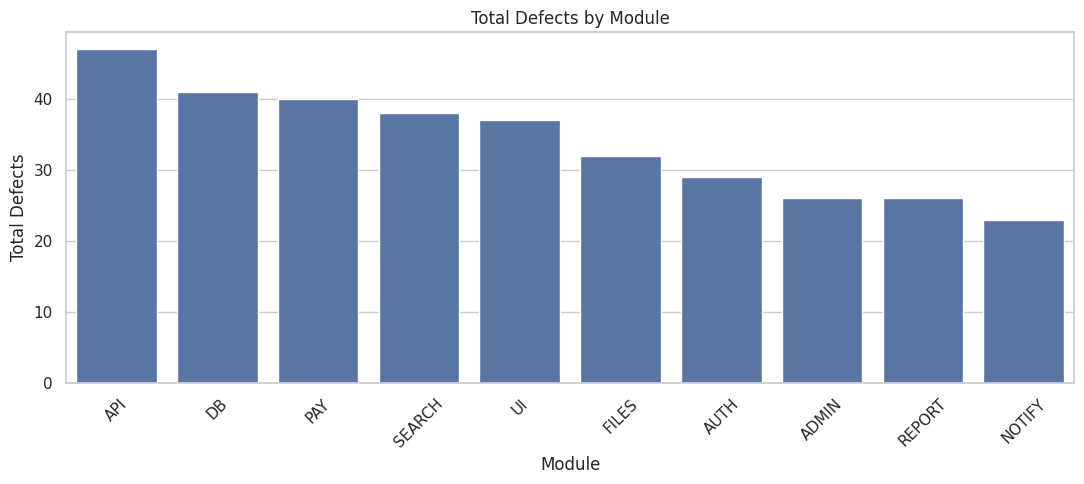

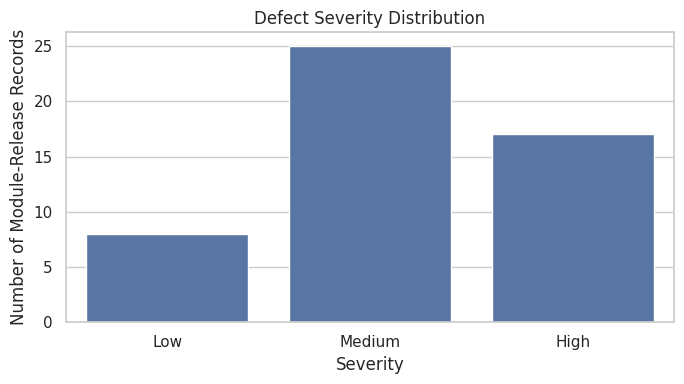

Module with the highest recorded defect total:


,module,defect_count
1,API,47


In [4]:

# Aggregate defects by module
module_defects = (
    df.groupby("module", as_index=False)["defect_count"]
    .sum(min_count=1)
    .sort_values("defect_count", ascending=False)
)

display(module_defects)

plt.figure(figsize=(11, 5))
sns.barplot(data=module_defects, x="module", y="defect_count")
plt.title("Total Defects by Module")
plt.xlabel("Module")
plt.ylabel("Total Defects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{PLOTS}/defects_by_module.png", dpi=150)
plt.show()

# Defect severity distribution
if "severity" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x="severity", order=["Low", "Medium", "High"])
    plt.title("Defect Severity Distribution")
    plt.xlabel("Severity")
    plt.ylabel("Number of Module-Release Records")
    plt.tight_layout()
    plt.savefig(f"{PLOTS}/severity_distribution.png", dpi=150)
    plt.show()

print("Module with the highest recorded defect total:")
display(module_defects.head(1))


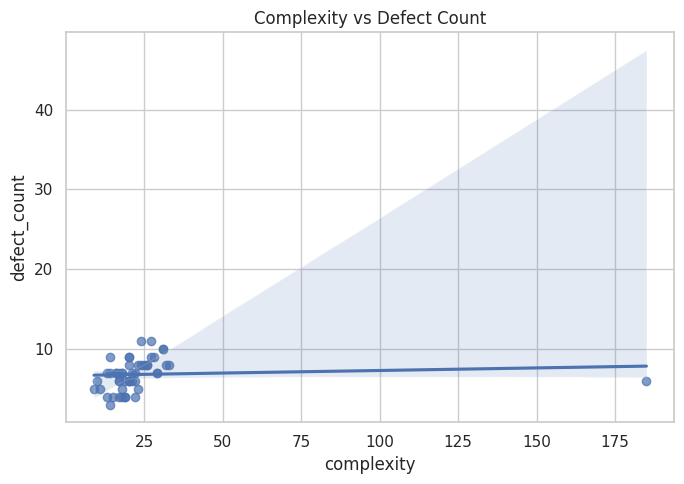

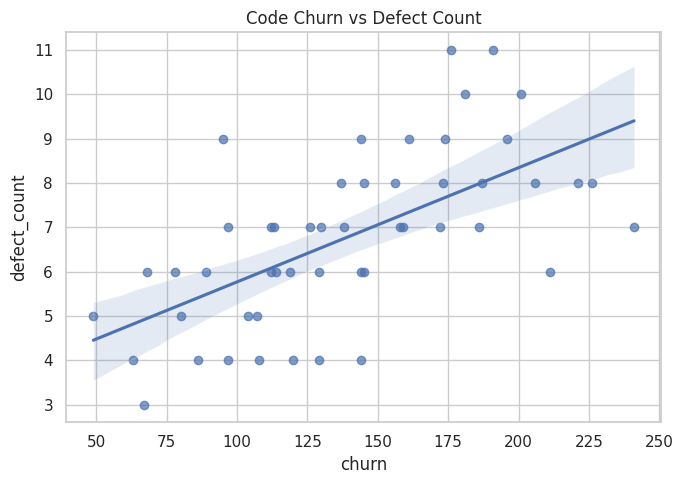

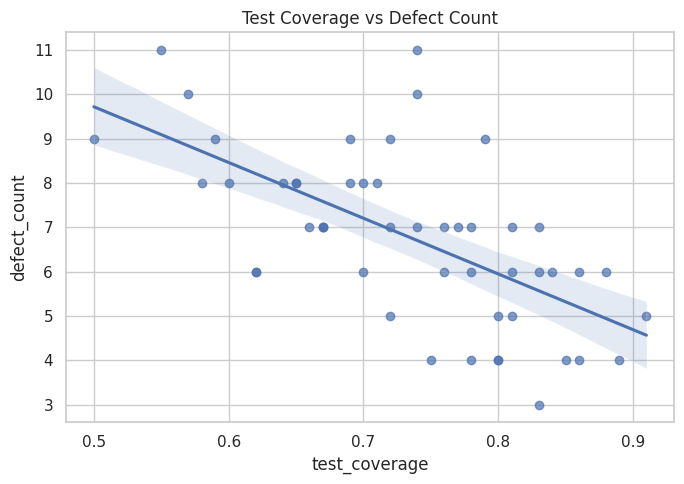

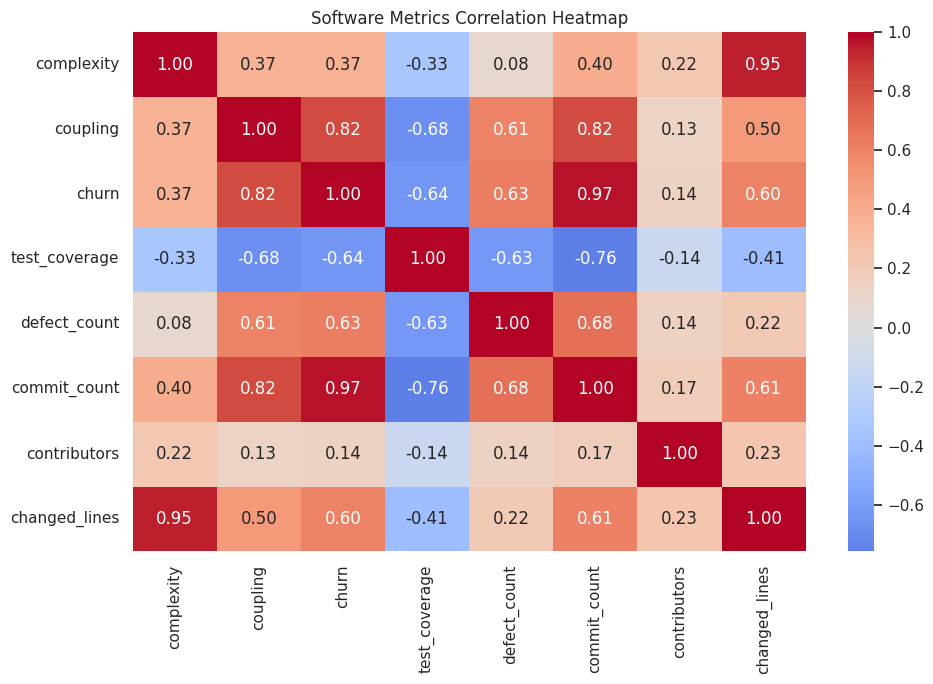

Correlation with defect count:


,defect_count
defect_count,1.000000
commit_count,0.677199
churn,0.625462
coupling,0.606907
changed_lines,0.215165
contributors,0.142001
complexity,0.080498
test_coverage,-0.631542


In [5]:

# Complexity vs defects
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df, x="complexity", y="defect_count",
    scatter_kws={"alpha": 0.7}
)
plt.title("Complexity vs Defect Count")
plt.tight_layout()
plt.savefig(f"{PLOTS}/complexity_vs_defects.png", dpi=150)
plt.show()

# Churn vs defects
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df, x="churn", y="defect_count",
    scatter_kws={"alpha": 0.7}
)
plt.title("Code Churn vs Defect Count")
plt.tight_layout()
plt.savefig(f"{PLOTS}/churn_vs_defects.png", dpi=150)
plt.show()

# Coverage vs defects
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df, x="test_coverage", y="defect_count",
    scatter_kws={"alpha": 0.7}
)
plt.title("Test Coverage vs Defect Count")
plt.tight_layout()
plt.savefig(f"{PLOTS}/coverage_vs_defects.png", dpi=150)
plt.show()

# Pearson correlations: useful for linear relationships, not proof of causation
corr_cols = [
    "complexity", "coupling", "churn", "test_coverage",
    "defect_count", "commit_count", "contributors", "changed_lines"
]
corr_cols = [c for c in corr_cols if c in df.columns]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Software Metrics Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{PLOTS}/correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation with defect count:")
display(
    corr[["defect_count"]].sort_values(
        "defect_count", ascending=False
    )
)


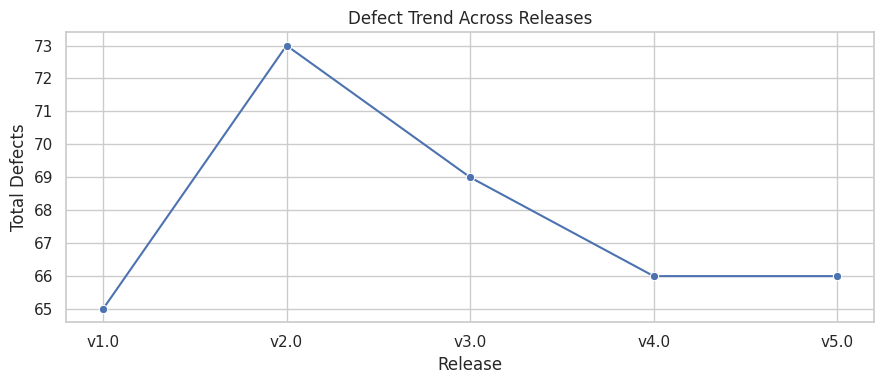

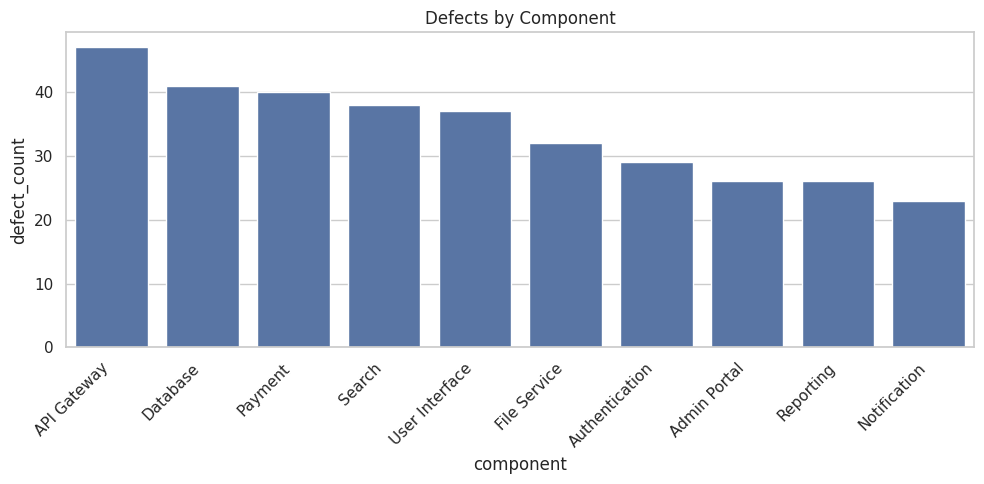

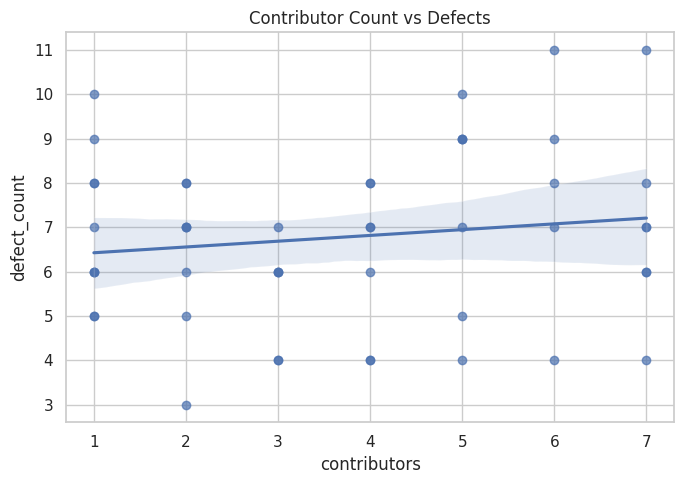

,release,defect_count
0,v1.0,65
1,v2.0,73
2,v3.0,69
3,v4.0,66
4,v5.0,66


,component,defect_count
0,API Gateway,47
3,Database,41
6,Payment,40
8,Search,38
9,User Interface,37
4,File Service,32
2,Authentication,29
1,Admin Portal,26
7,Reporting,26
5,Notification,23


In [6]:

# Defect trend by release
release_defects = (
    df.groupby("release", as_index=False)["defect_count"]
    .sum(min_count=1)
)

plt.figure(figsize=(9, 4))
sns.lineplot(
    data=release_defects, x="release", y="defect_count", marker="o"
)
plt.title("Defect Trend Across Releases")
plt.xlabel("Release")
plt.ylabel("Total Defects")
plt.tight_layout()
plt.savefig(f"{PLOTS}/defect_trend_by_release.png", dpi=150)
plt.show()

# Component analysis
component_defects = (
    df.groupby("component", as_index=False)["defect_count"]
    .sum(min_count=1)
    .sort_values("defect_count", ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=component_defects, x="component", y="defect_count"
)
plt.title("Defects by Component")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{PLOTS}/component_defects.png", dpi=150)
plt.show()

# Contributor analysis
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df, x="contributors", y="defect_count",
    scatter_kws={"alpha": 0.7}
)
plt.title("Contributor Count vs Defects")
plt.tight_layout()
plt.savefig(f"{PLOTS}/contributors_vs_defects.png", dpi=150)
plt.show()

display(release_defects)
display(component_defects)


In [7]:

# Engineered variables
# These are descriptive features; do not treat them as proof of causation.

df["coverage_gap"] = 1 - df["test_coverage"]

df["churn_per_commit"] = np.where(
    df["commit_count"] > 0,
    df["churn"] / df["commit_count"],
    np.nan
)

df["changed_lines_per_commit"] = np.where(
    df["commit_count"] > 0,
    df["changed_lines"] / df["commit_count"],
    np.nan
)

# Use fixed thresholds for an interpretable risk band.
df["complexity_risk_band"] = pd.cut(
    df["complexity"],
    bins=[-np.inf, 10, 20, 30, np.inf],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Create a repeated-defect flag from each module's observed release history.
# This is descriptive, not a feature for the same-row prediction model.
module_release_history = (
    df.groupby("module")["defect_count"]
    .sum(min_count=1)
    .rename("module_total_defects")
)
df = df.merge(
    module_release_history, on="module", how="left",
    validate="many_to_one"
)

df["repeated_defect_concern"] = (
    df["module_total_defects"] >=
    df["module_total_defects"].median()
).astype(int)

print("Engineered dataset:")
display(df.head())

df.to_csv(
    f"{PROCESSED}/software_quality_engineered.csv",
    index=False
)

print("Saved engineered dataset to:")
print(f"{PROCESSED}/software_quality_engineered.csv")


Engineered dataset:


,module,release,complexity,coupling,churn,test_coverage,component,language,size,defect_count,...,commit_count,contributors,changed_lines,release_date,coverage_gap,churn_per_commit,changed_lines_per_commit,complexity_risk_band,module_total_defects,repeated_defect_concern
0,PAY,v1.0,31.0,0.58,181,0.57,Payment,Java,6100,10,...,30,5,238,2022-02-15,0.43,6.033333,7.933333,Very High,40,1
1,API,v1.0,28.0,0.55,161,0.50,API Gateway,Python,3500,9,...,27,5,218,2022-02-15,0.50,5.962963,8.074074,High,47,1
2,DB,v1.0,33.0,0.64,145,0.64,Database,Java,5200,8,...,24,4,198,2022-02-15,0.36,6.041667,8.250000,Very High,41,1
3,UI,v1.0,18.0,0.35,130,0.67,User Interface,TypeScript,4800,7,...,23,4,183,2022-02-15,0.33,5.652174,7.956522,Moderate,37,1
4,NOTIFY,v1.0,11.0,0.26,49,0.81,Notification,Python,2100,5,...,12,1,118,2022-02-15,0.19,4.083333,9.833333,Moderate,23,0


Saved engineered dataset to:
/content/Software-Quality-Insight/data/processed/software_quality_engineered.csv


In [8]:

# Summarize only actual calculated results
valid_corr = corr["defect_count"].drop("defect_count", errors="ignore").dropna()

print("========== EDA FINDINGS ==========")

if not module_defects.empty and module_defects["defect_count"].notna().any():
    top_module = module_defects.dropna(subset=["defect_count"]).iloc[0]
    print(
        f"1. Highest total defects: {top_module['module']} "
        f"({top_module['defect_count']:.0f} recorded defects)."
    )

if not valid_corr.empty:
    strongest = valid_corr.abs().idxmax()
    value = valid_corr[strongest]
    direction = "positive" if value > 0 else "negative"
    print(
        f"2. Strongest absolute Pearson correlation with defects: "
        f"{strongest} (r = {value:.3f}, {direction})."
    )
else:
    print("2. Not enough valid data to calculate correlations.")

print("\nThese are descriptive associations, not evidence of causation.")

# Download engineered dataset
files.download(f"{PROCESSED}/software_quality_engineered.csv")


========== EDA FINDINGS ==========
1. Highest total defects: API (47 recorded defects).
2. Strongest absolute Pearson correlation with defects: commit_count (r = 0.677, positive).

These are descriptive associations, not evidence of causation.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>